# Reading and storing a large (>1,000) number of spectra



<img style="position: absolute; right: 60px; top: 40px; height: 160px; width: 160px" src="https://datalabs.esa.int/datalab-icon/c11e47af-7ce9-4281-b3b5-475a180a256f" /> 


<div style="width: 70%;">

Copyright (c) European Space Agency, 2026.

This file is subject to the terms and conditions defined in file LICENSE.txt, which is part of this source code package. No part of the package, including this file, may be copied, modified, propagated, or distributed except according to the terms contained in the file LICENSE.txt.

</div>

**Last modified:** 2026-11-11

**Last update:** DR1-Foundation major update.

**Notebook summary**

This notebook shows how to read many (>1,000) spectra files using parallelisation tools available in Python.

Caveats:

1. Parallelisation is achieved via the [concurrent](https://docs.python.org/3/library/concurrent.futures.html) Python package. The core tools of this notebook are included in the associated "utils_mspec.py" file.
2. The notebook stores the spectra in local, FITS MEF files named, by default, as "chunk_0.fits, ..., chunk_n.fits", where each chunk can contain up to 2,000 hdu (spectra).
3. The code generates a "metadata" table that allows to map the content of each chunk - in other workds: to easily find which chunk (and HDU index) contains the spectra for a given source.


**Please note:**

* This execution is CPU intensive, and at times (during peak load) the Datalabs may become slow and even not responsible. 
* Validation tests point to an average writting time of ~0.15 seconds per spectra. The chunk size has negligible impact in this.


**Useful links:**

* [Euclid DR1 data product description](https://euclid.esac.esa.int/dr/dr1/dpdd/)
* [Euclid Q1 data product description](https://euclid.esac.esa.int/dr/q1/dpdd/index.html)
* [DR1 data release homepage](https://www.cosmos.esa.int/web/euclid/euclid-dr1)
* [Euclid Q1 data product description](https://euclid.esac.esa.int/dr/q1/dpdd/index.html)
* [Euclid Astroquery documentation](https://astroquery.readthedocs.io/en/latest/esa/euclid/euclid.html)

**Running the notebook:**

* This notebook has **read-only permissions**. You can still run and edit cells but if you would like to save your changes then you have to save the notebook to a different location - your workspace for example. 
* The notebook is intended to be run using the **EUCLID-TOOLS kernel** that has all the necessary packages included.
* The notebook uses functions from the **utils_mspec.py** Python file. When moving the notebook you need to move this file as well. You are welcome to modify the utility file for any custom/advanced behaviour you may need.

**Version:**

* Content updated in preparation for the Euclid DR1-Foundation.
***

In [1]:
# importing necessary packages
import os, time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random
from concurrent.futures import ProcessPoolExecutor

from astropy.io import fits
from astropy.table import Table
from astropy import units as u
from astroquery.esa.euclid.core import Euclid

import utils_mspec as utils

import warnings
from astropy.units import UnitsWarning
warnings.simplefilter("ignore", UnitsWarning)

First let's make a folder (if not already created) to save the output files from this notebook. All the example notebooks save their outputs to this same folder in your user workspace called: `'example_notebook_outputs/'`

In [2]:
#make a folder in your workspace for the output files
output_folder = '/media/user/example_notebook_outputs/'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

**Please note:** When comparing the Q1 and DR1-foundation data release content:
* some table and column names will be different
* specific examples may yield different results

It is possible to login using many different options - see the # [Euclid.login](https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass.login) method for details. Similarly to the archive website for safety reasons this login expires after a period of time. Once this happens the queries to the archive will fail (seemingly without reason). If you are running a personal notebook that requires you to stay logged in for longer - make sure to execute this code line again every once in a while. 

In [3]:
# Alternative ways to login; uncomment your preferred one: ===========
Euclid.login()
# Euclid.login_gui()                                          # Login via graphic interface (pop-up window)
# Euclid.login(user='<user name>', password='<password>')     # 
# Euclid.logout()

INFO: Login to Euclid TAP server: eas.esac.esa.int:443/tap-server/tap/ [astroquery.esa.euclid.core]


User:  hcanovas
Password:  ········


INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid data service: eas.esac.esa.int:443/sas-dd/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid cutout service: eas.esac.esa.int:443/sas-cutout/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid sia service: eas.esac.esa.int:443/sas-sia/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]


In [4]:
schema = 'dr1'   # DR1 schema. Change to "q1" to retrieve Q1 data, but please note that the target table names should be adapted accordingly. 

## 1.- Use case: Store locally (in chunks) the XX spectra included in a cone search around NGC 6505

Note: To ensure that this example is finished in less than a minute, the cone search radius has been set to 0.025 degrees, which results in a very small sample of 134 spectra. With this setup the code reads spectra at ~0.25 second per spectra. In this regime, the total computing time is dominated by the reading and writting overheads. Our tests show that the performance improves when increasing the input sample size, reaching an average performance of ~0.1 second/spectra.

In [5]:
Euclid.ROW_LIMIT = -1
radius           = 0.025*u.deg # Increasing to 0.1 degrees return a sample of 6,443 sources.
coordinate       = 'NGC 6505'

job = Euclid.cone_search(coordinate=coordinate, radius = radius, 
                         columns=['source_id', 'datalabs_path', 'file_name', 'hdu_index', 'ra_obj', 'dec_obj'], 
                         table_name=f'{schema}.spectra_source_deep', ra_column_name="ra_obj", dec_column_name="dec_obj",
                         async_job=True)
res = job.get_results()
print(f'Output table contains {len(res)} rows')
res[0:3]

INFO: Query finished. [astroquery.utils.tap.core]
Output table contains 134 rows


source_id,datalabs_path,file_name,hdu_index,ra_obj,dec_obj,dist
int64,object,object,int64,float64,float64,float64
2677813145655310071,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101832848,EUC_SIR_W-COMBSPEC_101832848_20250907T180646.300586Z.fits,5472,267.781314542767,65.5310071995461,0.00029405361640638764
2677813145655310071,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101832848,EUC_SIR_W-COMBSPEC_101832848_20250908T235107.190249Z.fits,11218,267.781314542767,65.5310071995461,0.00029405361640638764
2677928616655368778,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101832848,EUC_SIR_W-COMBSPEC_101832848_20250907T180646.300586Z.fits,5514,267.792861609469,65.5368778946172,0.007865984420434598


### 1.1 Store results in chunks of XX elements 

Reminder: the max. chunk size is 2000.

In [6]:
c_size    = 50  # Chunk  size.

s_time    = time.time()
chunks    = utils.make_chunks(res, c_size)
metadata  = utils.create_mef_files(chunks, output_folder = output_folder, verbose = True, metadata_table = 'metadata_table.csv')
e_time    = float(time.time() - s_time)

print()
print(f'Chunk size = {c_size} - Performance: {e_time/len(res):5.2f} second per spectra (including all overheads)')
print(f'* Total computing time: {e_time:4.2f} seconds ({e_time/60.:3.1f} minutes)')

display(metadata[0:3])

* Input table with 134 rows is split into 3 chunks of 50 each (except for the last chunk that contains 34 elements).
* Chunk:    0 stored as:            /media/user/example_notebook_outputs/chunk_0.fits - It contains 50 spectra + 1 primary HDU
* Chunk:    1 stored as:            /media/user/example_notebook_outputs/chunk_1.fits - It contains 50 spectra + 1 primary HDU
* Chunk:    2 stored as:            /media/user/example_notebook_outputs/chunk_2.fits - It contains 34 spectra + 1 primary HDU
* Metadata table stored as: /media/user/example_notebook_outputs/metadata_table.csv

Chunk size = 50 - Performance:  1.64 second per spectra (including all overheads)
* Total computing time: 220.22 seconds (3.7 minutes)


,source_id,ra,dec,fits_file,hdu_index
0,2677813145655310071,267.781315,65.531007,/media/user/example_notebook_outputs/chunk_0.fits,1
1,2677813145655310071,267.781315,65.531007,/media/user/example_notebook_outputs/chunk_0.fits,2
2,2677928616655368778,267.792862,65.536878,/media/user/example_notebook_outputs/chunk_0.fits,3


### 1.2 Plot the spectra of a selected source


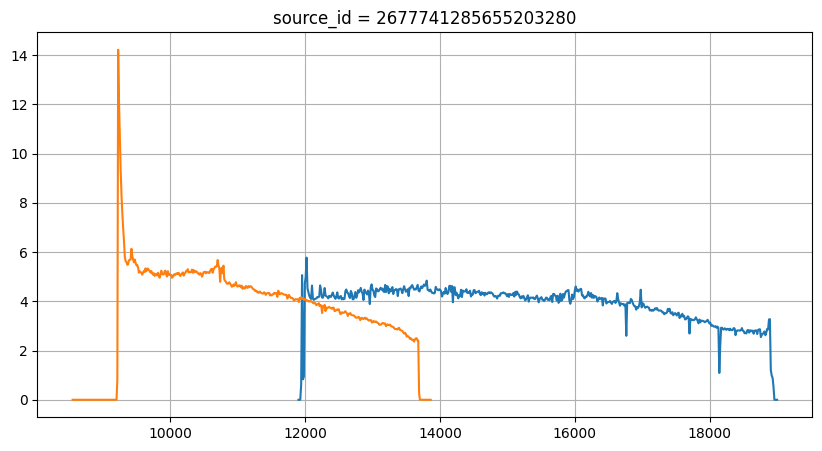

In [7]:
source_id = 2677741285655203280
indexes   = metadata.loc[metadata['source_id'] == source_id, :].index

spec_list = []
for index in indexes:
    fits_file = metadata['fits_file'][index]
    hdu       = metadata['hdu_index'][index]
    spec_list.append(Table.read(fits_file, hdu))
    
fig = plt.figure(figsize=[10,5])
plt.title(f"source_id = {metadata['source_id'][indexes[0]]}")
for spec in spec_list:
    plt.plot(spec['WAVELENGTH'], spec['SIGNAL'])

plt.grid()
plt.show()

## 2.- Use case: Store locally (in chunks) the TOP XX spectra included in sample of MER sources with ellipticity <0.2 (Q1)

Note: To ensure that this example is finished in less than a minute, the query only retrieves data for 170 sources. With this setup the code reads spectra at ~0.25 second per spectra. In this regime, the total computing time is dominated by the reading and writting overheads. Our tests show that the performance improves when increasing the input sample size, reaching an average performance of ~0.1 second/spectra.

In [8]:
top_val = 170
query   = f"""SELECT TOP {top_val} mer.ellipticity, spec.*
FROM {schema}.spectra_source_deep AS spec
JOIN {schema}.mer_catalogue_deep_survey AS mer
  ON mer.object_id = spec.source_id
WHERE mer.ellipticity <0.2"""


job = Euclid.launch_job_async(query = query, output_format='ecsv')
res = job.get_results()
print(f'Output table contains {len(res)} rows')
res[0:3]

INFO: Query finished. [astroquery.utils.tap.core]
Output table contains 170 rows


ellipticity,calblock_id_list,combined_spectra_fk,combined_spectra_product_fk,datalabs_path,dec_obj,dith_num,file_name,file_path,hdu_index,patch_id_list,ra_obj,source_id,spectra_source_oid,to_be_published
NA,,,,,,,,,,,,,,
float64,object,int64,int64,str55,float64,int64,str57,str65,int64,int64[10],float64,int64,int64,int32
0.07797040790319443,['CALBLOCK-F-003'],14335,1241652,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101283349,-48.3880019220662,43,EUC_SIR_W-COMBSPEC_101283349_20251017T075852.673708Z.fits,/data/euclid/repository_dr1/DR1/R1/SIR_COMBINED_SPECTRA/101283349,11446,62 .. 126,62.9514366997473,-629514366483880019,296341950,1
0.04758299142122269,['CALBLOCK-F-002'],712,44512,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101366964,-29.7428414086556,4,EUC_SIR_W-COMBSPEC_101366964_20250821T091052.426861Z.fits,/data/euclid/repository_dr1/DR1/R1/SIR_COMBINED_SPECTRA/101366964,955,58 .. 0,53.6636467732007,-536636467297428414,4381633,1
0.1914883404970169,['CALBLOCK-F-003'],14321,1240562,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101281450,-48.9927900198828,12,EUC_SIR_W-COMBSPEC_101281450_20251017T043135.946244Z.fits,/data/euclid/repository_dr1/DR1/R1/SIR_COMBINED_SPECTRA/101281450,4872,71 .. 0,65.7894779093353,-657894779489927900,296087323,1


### Store results in chunks of XX elements 

Remember that chunks cannot contain more than 2,000 elements.

In [9]:
c_size    = 50  # Chunk  size.

s_time    = time.time()
chunks    = utils.make_chunks(res, c_size)
metadata  = utils.create_mef_files(chunks, output_folder = output_folder, verbose = True, metadata_table = 'metadata_table.csv')
e_time    = float(time.time() - s_time)

print()
print(f'Chunk size = {c_size} - Performance: {e_time/len(res):5.2f} second per spectra (including all overheads)')
print(f'* Total computing time: {e_time:4.2f} seconds ({e_time/60.:3.1f} minutes)')

display(metadata[0:3])

* Input table with 170 rows is split into 4 chunks of 50 each (except for the last chunk that contains 20 elements).
* Chunk:    0 stored as:            /media/user/example_notebook_outputs/chunk_0.fits - It contains 50 spectra + 1 primary HDU
* Chunk:    1 stored as:            /media/user/example_notebook_outputs/chunk_1.fits - It contains 50 spectra + 1 primary HDU
* Chunk:    2 stored as:            /media/user/example_notebook_outputs/chunk_2.fits - It contains 50 spectra + 1 primary HDU
* Chunk:    3 stored as:            /media/user/example_notebook_outputs/chunk_3.fits - It contains 20 spectra + 1 primary HDU
* Metadata table stored as: /media/user/example_notebook_outputs/metadata_table.csv

Chunk size = 50 - Performance:  1.03 second per spectra (including all overheads)
* Total computing time: 175.94 seconds (2.9 minutes)


,source_id,ra,dec,fits_file,hdu_index
0,-629514366483880019,62.951437,-48.388002,/media/user/example_notebook_outputs/chunk_0.fits,1
1,-536636467297428414,53.663647,-29.742841,/media/user/example_notebook_outputs/chunk_0.fits,2
2,-657894779489927900,65.789478,-48.992790,/media/user/example_notebook_outputs/chunk_0.fits,3


### 1.2 Plot the spectra of a selected source


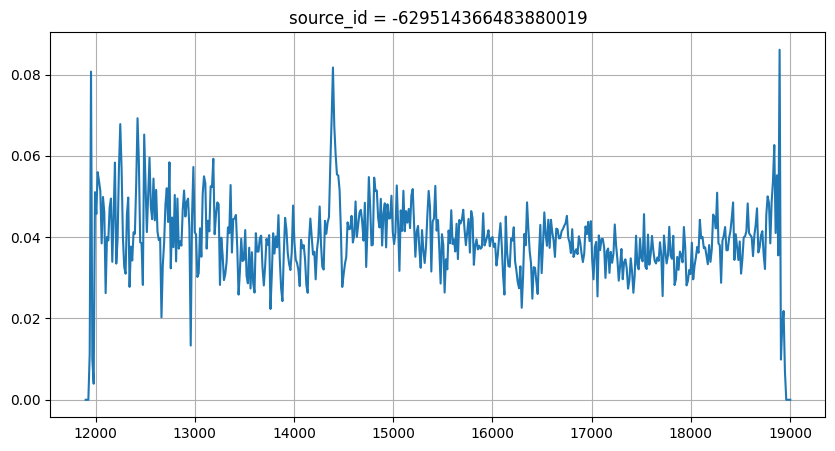

In [10]:
source_id = metadata['source_id'][0]         # Selecting first source_id in metadata table.
indexes   = metadata.loc[metadata['source_id'] == source_id, :].index

spec_list = []
for index in indexes:
    fits_file = metadata['fits_file'][index]
    hdu       = metadata['hdu_index'][index]
    spec_list.append(Table.read(fits_file, hdu))
    
fig = plt.figure(figsize=[10,5])
plt.title(f"source_id = {metadata['source_id'][indexes[0]]}")
for spec in spec_list:
    plt.plot(spec['WAVELENGTH'], spec['SIGNAL'])

plt.grid()
plt.show()